# Phase 2: Tumour segmentation (kritikaa, patient 22)

I search for the tumour inside the liver with Niblack, statistical region growing and a geodesic active contour. Each is scored with the ground-truth liver, the predicted liver and its convex hull.

## Step 0: Setup

Imports, folders and charvi's liver pipeline for the predicted liver.

In [1]:
import os
import glob
import sys
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy import ndimage as ndi
from skimage.filters import threshold_niblack
from skimage.measure import label, regionprops
from skimage.segmentation import morphological_geodesic_active_contour, inverse_gaussian_gradient

sys.path.insert(0, "../app")
import pipeline_charvi                     # the group's liver segmentation, used for the "predicted liver" scores

NAME = "kritikaa"
ENH = "../phase1/outputs_kritikaa/enhanced"     # Phase 1 output
GT = "../data/slices/" + NAME                   # ground-truth masks
OUT = "outputs_kritikaa"
FIGS = "../report/figures/kritikaa"
FAILED = "../report/failed_cases/kritikaa"
METHODS = ["niblack", "regiongrow", "gac"]
for m in METHODS:
    os.makedirs(OUT + "/" + m, exist_ok=True)
os.makedirs(OUT + "/predicted_liver", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)
os.makedirs(FAILED, exist_ok=True)

# list all the enhanced slices from Phase 1
files = sorted(glob.glob(ENH + "/*_enh.png"))
print(len(files), "enhanced slices found")

12 enhanced slices found


In [2]:
def load(p):
    # enhanced image (0-255) + ground-truth liver mask + ground-truth tumour mask
    slice_id = os.path.basename(p).replace("_enh.png", "")
    enhanced_img = cv2.imread(p, 0)
    liver_mask = cv2.imread(GT + "/" + slice_id + "_liver.png", 0) > 0
    gt_mask = cv2.imread(GT + "/" + slice_id + "_tumour.png", 0) > 0
    return slice_id, enhanced_img, liver_mask, gt_mask


def dice(pred_mask, gt_mask):
    # Dice = 2|A n B| / (|A| + |B|). 1 = perfect overlap, 0 = none
    overlap = (pred_mask & gt_mask).sum()
    return 2 * overlap / (pred_mask.sum() + gt_mask.sum() + 1e-9)


def iou(pred_mask, gt_mask):
    # Jaccard / IoU = |A n B| / |A u B|
    overlap = (pred_mask & gt_mask).sum()
    union = (pred_mask | gt_mask).sum()
    return overlap / (union + 1e-9)


def overlay(img, pred_mask, gt_mask):
    # RED = predicted outline, GREEN = ground-truth outline
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    contours, _ = cv2.findContours(gt_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(rgb, contours, -1, (0, 255, 0), 2)
    contours, _ = cv2.findContours(pred_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(rgb, contours, -1, (255, 0, 0), 2)
    return rgb

## Step 1: The example slice

The slice with the biggest tumour, zoomed on the liver.

example slice: p22_s132


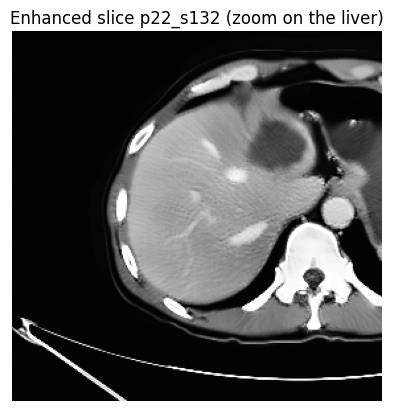

In [3]:
# example slice for the figures: the one with the biggest tumour
example = files[0]
biggest = -1
for f in files:
    slice_id, enhanced_img, liver_mask, gt_mask = load(f)
    if gt_mask.sum() > biggest:
        biggest = gt_mask.sum()
        example = f

sid, img, liver, gt = load(example)
print("example slice:", sid)

# zoom window on the liver used in all figures
r0 = 120
r1 = 400
c0 = 40
c1 = 320

# read the image -> show it
plt.figure()
plt.imshow(img[r0:r1, c0:c1], cmap='gray')
plt.title('Enhanced slice ' + sid + ' (zoom on the liver)')
plt.axis('off')
plt.show()

## Step 2: Structuring elements and a first threshold

My plus-shaped elements, then a rough threshold at the liver median - 30 and the four basic operations.

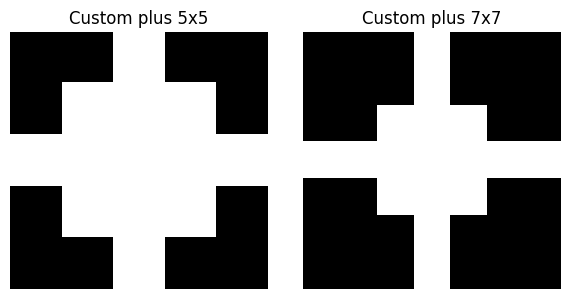

In [4]:
# ---- structuring elements ----
# hand-made plus shapes: closer to a round tumour than a square
SE_PLUS_5 = np.zeros((5, 5), np.uint8)     # opening
SE_PLUS_5[2, :] = 1
SE_PLUS_5[:, 2] = 1
SE_PLUS_5[1:4, 1:4] = 1
SE_PLUS_7 = np.zeros((7, 7), np.uint8)     # closing
SE_PLUS_7[3, :] = 1
SE_PLUS_7[:, 3] = 1
SE_PLUS_7[2:5, 2:5] = 1

se_list = [SE_PLUS_5, SE_PLUS_7]
se_titles = ["Custom plus 5x5", "Custom plus 7x7"]
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for i in range(2):
    ax[i].imshow(se_list[i], cmap="gray")
    ax[i].set_title(se_titles[i])
    ax[i].axis("off")
plt.tight_layout()
plt.show()

In [5]:
def liver_roi(liver):
    # erode the liver a little (5x5 square) so its dark border is not mistaken for tumour
    square_5 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    return cv2.erode(liver.astype(np.uint8), square_5) > 0


def remove_small(mask, min_area=30):
    # connected components -> keep only the blobs with at least min_area pixels
    lab = label(mask)
    keep = []
    for r in regionprops(lab):
        if r.area >= min_area:
            keep.append(r.label)
    return np.isin(lab, keep)


def tidy(mask):
    # same clean-up for every method: opening, drop tiny blobs, closing, fill holes
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, SE_PLUS_5) > 0
    mask = remove_small(mask)
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, SE_PLUS_7) > 0
    return ndi.binary_fill_holes(mask)

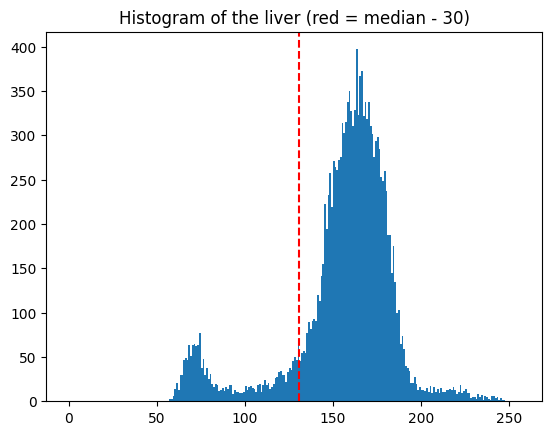

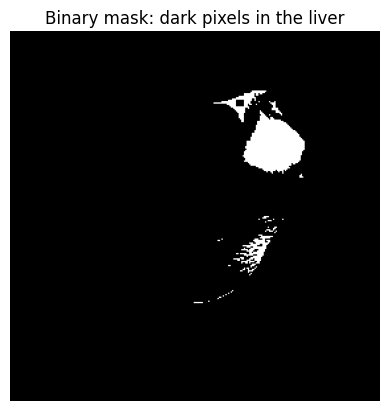

In [6]:
# look at the histogram of the liver to get a threshold (tumour = the dark side)
roi = liver_roi(liver)
rough_threshold = np.median(img[roi]) - 30

plt.figure()
plt.hist(img[roi].ravel(), bins=256, range=(0, 256))
plt.axvline(rough_threshold, color='red', linestyle='--')
plt.title('Histogram of the liver (red = median - 30)')
plt.show()

# makes a binary image: dark pixels inside the liver are 1 (white), the rest 0 (black)
rough = ((img < np.median(img[roi]) - 30) & roi).astype(np.uint8)
plt.figure()
plt.imshow(rough[r0:r1, c0:c1], cmap='gray')
plt.title('Binary mask: dark pixels in the liver')
plt.axis('off')
plt.show()

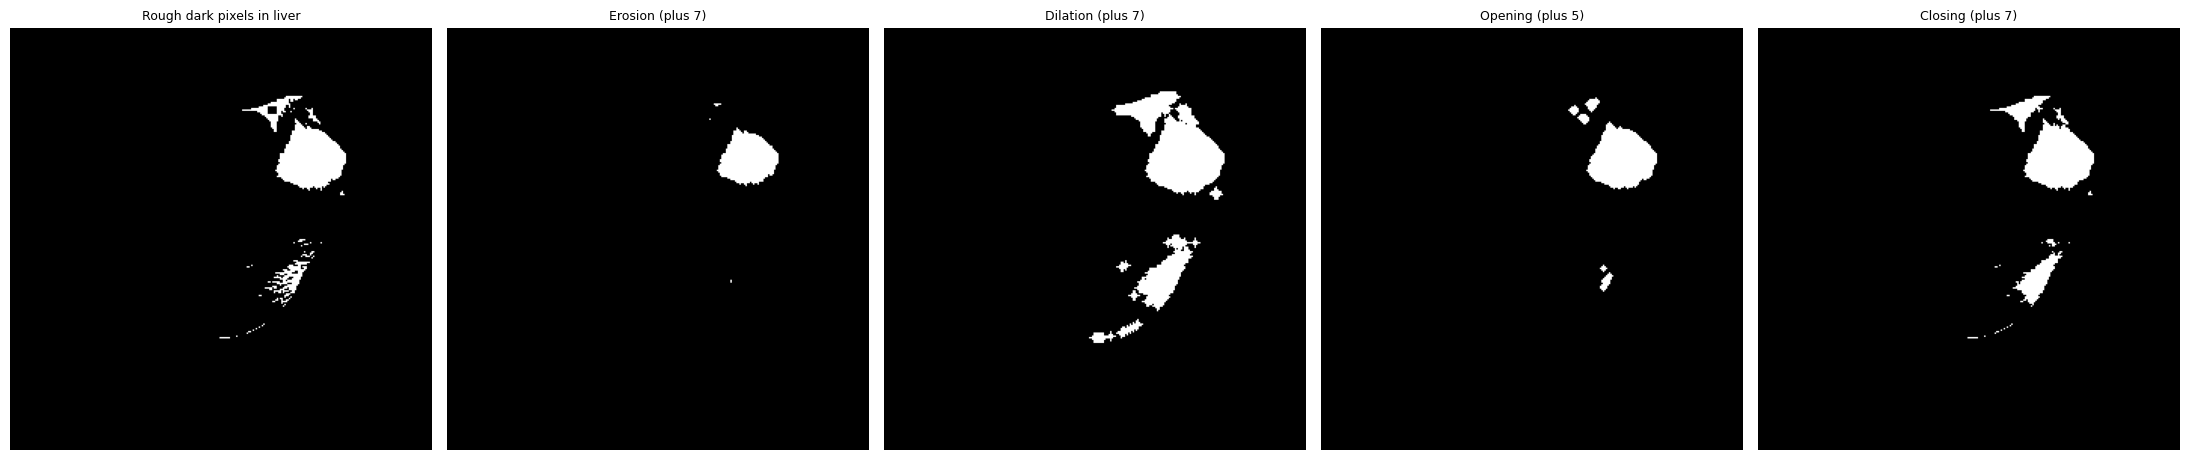

In [7]:
# erosion, dilation, opening and closing on the rough binary mask
eroded = cv2.erode(rough, SE_PLUS_7)
dilated = cv2.dilate(rough, SE_PLUS_7)
opened = cv2.morphologyEx(rough, cv2.MORPH_OPEN, SE_PLUS_5)       # erode then dilate: removes specks
closed = cv2.morphologyEx(rough, cv2.MORPH_CLOSE, SE_PLUS_7)      # dilate then erode: fills holes

# save the comparison figure for the report
morph_images = [rough, eroded, dilated, opened, closed]
morph_titles = ["Rough dark pixels in liver", "Erosion (plus 7)", "Dilation (plus 7)", "Opening (plus 5)", "Closing (plus 7)"]
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for i in range(5):
    ax[i].imshow(morph_images[i][r0:r1, c0:c1], cmap="gray")
    ax[i].set_title(morph_titles[i], fontsize=9)
    ax[i].axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_morphology.png", dpi=120)
plt.show()

## Step 3: Method A, Niblack

T = local mean - 1.0 x local std in a 101 x 101 window; pixels darker than T are tumour.

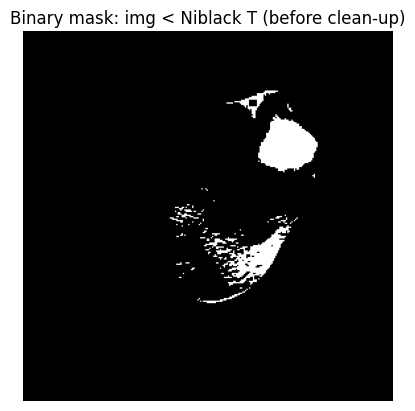

In [8]:
# ---- Method A: Niblack local threshold ----
NIBLACK_WINDOW = 101
NIBLACK_K = 1.0


def segment_niblack(img, liver):
    roi = liver_roi(liver)
    if roi.sum() < 50:
        return np.zeros(img.shape, bool)
    # outside the liver = liver median, so the background does not lower the local mean
    filled = np.where(roi, img, np.median(img[roi])).astype(float)
    # T = local mean - k x local std, one threshold per pixel
    T = threshold_niblack(filled, window_size=NIBLACK_WINDOW, k=NIBLACK_K)
    return tidy((img < T) & roi)


filled = np.where(liver_roi(liver), img, np.median(img[liver_roi(liver)])).astype(float)
T = threshold_niblack(filled, window_size=NIBLACK_WINDOW, k=NIBLACK_K)

# makes a binary image: darker than the local threshold T, inside the liver
niblack_binary = (img < T) & liver_roi(liver)
plt.figure()
plt.imshow(niblack_binary[r0:r1, c0:c1], cmap='gray')
plt.title('Binary mask: img < Niblack T (before clean-up)')
plt.axis('off')
plt.show()

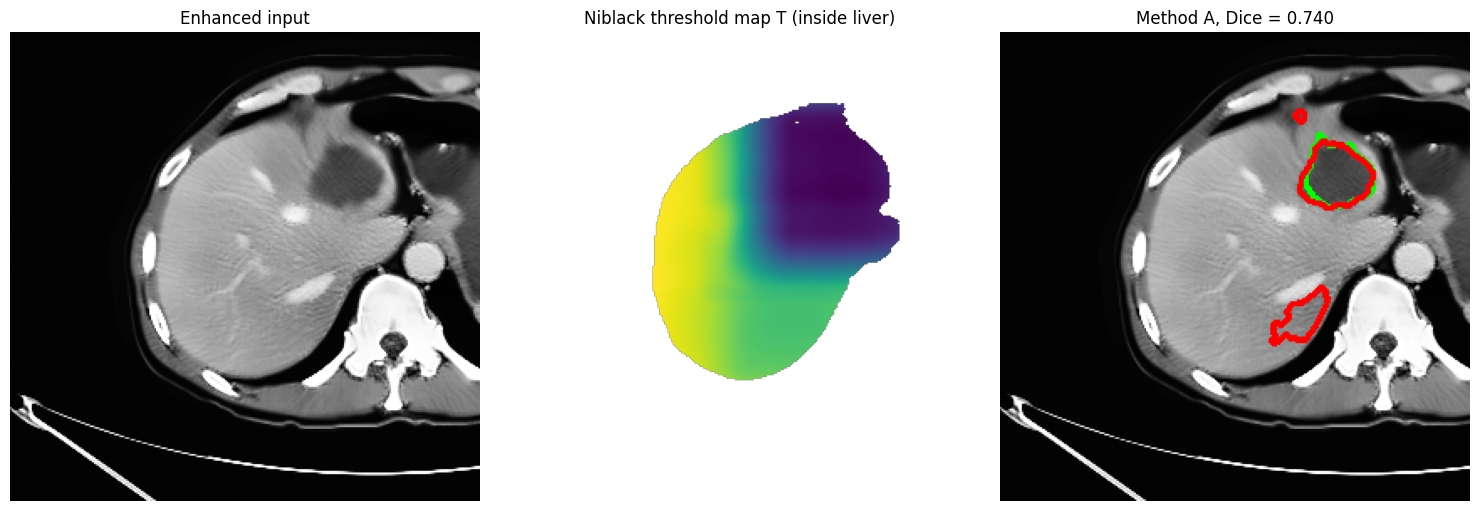

In [9]:
pred_a = segment_niblack(img, liver)

# save the comparison figure for the report
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img[r0:r1, c0:c1], cmap="gray")
ax[0].set_title("Enhanced input")
ax[1].imshow(np.where(liver, T, np.nan)[r0:r1, c0:c1], cmap="viridis")
ax[1].set_title("Niblack threshold map T (inside liver)")
ax[2].imshow(overlay(img, pred_a, gt)[r0:r1, c0:c1])
ax[2].set_title(f"Method A, Dice = {dice(pred_a, gt):.3f}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_method_a_niblack.png", dpi=120)
plt.show()

## Step 4: Method B, statistical region growing

Seeds at the centroids of dark spots; a pixel joins if it is within 2.5 x std of the region mean. Regions over half the liver are rejected.

In [10]:
# ---- Method B: statistical seeded region growing ----
K_DARK = 2.0          # candidate spots: darker than liver median - K_DARK x std
GROW_K = 2.5          # join if |pixel - region mean| <= GROW_K x max(region std, GROW_FLOOR)
GROW_FLOOR = 4.0


def dark_candidates(img, liver):
    # dark spots inside the liver = where a tumour may be. Shared starting point for methods B and C
    roi = liver_roi(liver)
    if roi.sum() < 50:
        return np.zeros(img.shape, bool)
    smooth = cv2.GaussianBlur(img, (5, 5), 0)   # Gaussian smoothing
    med = np.median(smooth[roi])
    sd = smooth[roi].std()
    dark = ((smooth < med - K_DARK * sd) & roi).astype(np.uint8)   # threshold
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, SE_PLUS_5) > 0   # opening
    return remove_small(dark)


def centroid_seed(r):
    # candidate pixel closest to its centroid
    cy, cx = r.centroid
    distances = (r.coords[:, 0] - cy) ** 2 + (r.coords[:, 1] - cx) ** 2
    return tuple(r.coords[np.argmin(distances)])

In [11]:
def statistical_region_grow(img, seed, allowed, k=GROW_K, floor=GROW_FLOOR):
    # a 4-neighbour joins if it is within k x std of the region mean
    # (mean and std updated after every pixel, Welford)
    h, w = img.shape
    y0, x0 = seed
    start = img[max(y0 - 2, 0):y0 + 3, max(x0 - 2, 0):x0 + 3].astype(float).ravel()   # 5x5 start statistics
    n = len(start)
    mean = start.mean()
    m2 = ((start - mean) ** 2).sum()                                                    # sum of squared differences
    region = np.zeros((h, w), bool)
    region[seed] = True
    stack = [seed]
    while stack:
        y, x = stack.pop()
        for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            yy = y + dy
            xx = x + dx
            if 0 <= yy < h and 0 <= xx < w and not region[yy, xx] and allowed[yy, xx]:
                v = float(img[yy, xx])
                if abs(v - mean) <= k * max(np.sqrt(m2 / n), floor):
                    region[yy, xx] = True
                    stack.append((yy, xx))
                    n += 1
                    d = v - mean
                    mean += d / n
                    m2 += d * (v - mean)
    return region


def segment_region_growing(img, liver, return_seeds=False):
    roi = liver_roi(liver)
    out = np.zeros(img.shape, bool)
    seeds = []
    smooth = cv2.GaussianBlur(img, (5, 5), 0)
    for r in regionprops(label(dark_candidates(img, liver))):
        seed = centroid_seed(r)
        grown = statistical_region_grow(smooth, seed, roi)
        if grown.sum() < 0.5 * roi.sum():          # a region that floods more than half the liver leaked
            out |= grown
            seeds.append(seed)
    out = tidy(out)
    if return_seeds:
        return out, seeds
    else:
        return out

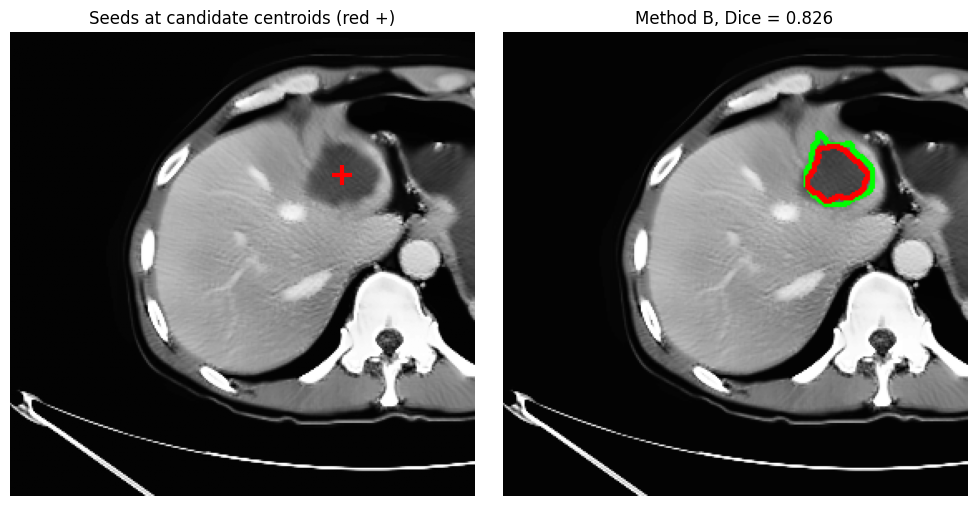

In [12]:
pred_b, seeds = segment_region_growing(img, liver, return_seeds=True)

# save the comparison figure for the report
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img[r0:r1, c0:c1], cmap="gray")
for s in seeds:
    ax[0].plot(s[1] - c0, s[0] - r0, "r+", markersize=15, mew=3)
ax[0].set_title("Seeds at candidate centroids (red +)")
ax[1].imshow(overlay(img, pred_b, gt)[r0:r1, c0:c1])
ax[1].set_title(f"Method B, Dice = {dice(pred_b, gt):.3f}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_method_b_regiongrow.png", dpi=120)
plt.show()

## Step 5: Method C, geodesic active contour

The dark spots grow outwards for 50 iterations and stop at strong edges.

In [13]:
# ---- Method C: geodesic active contour ----
# the edge-stopping image uses a Gaussian and the image gradient
GAC_ITERATIONS = 50
GAC_ALPHA = 100
GAC_SIGMA = 2


def segment_gac(img, liver, return_init=False):
    roi = liver_roi(liver)
    start = dark_candidates(img, liver)
    if not start.any():
        if return_init:
            return np.zeros(img.shape, bool), start
        else:
            return np.zeros(img.shape, bool)
    edge_stop = inverse_gaussian_gradient(img / 255.0, alpha=GAC_ALPHA, sigma=GAC_SIGMA)   # ~0 on edges, ~1 in flat areas
    level_set = morphological_geodesic_active_contour(edge_stop, num_iter=GAC_ITERATIONS, init_level_set=start.astype(np.int8),
                                                     smoothing=1, balloon=1, threshold="auto")
    out = tidy((level_set > 0) & roi)
    if return_init:
        return out, start
    else:
        return out

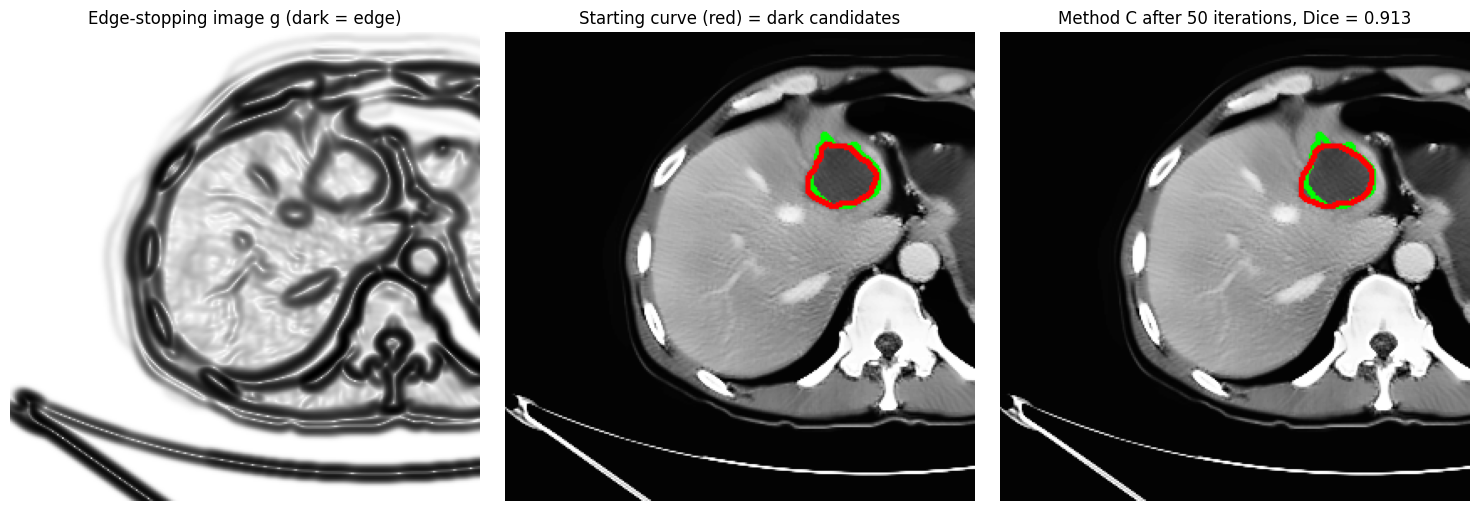

In [14]:
pred_c, start = segment_gac(img, liver, return_init=True)
edge_stop = inverse_gaussian_gradient(img / 255.0, alpha=GAC_ALPHA, sigma=GAC_SIGMA)

# save the comparison figure for the report
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(edge_stop[r0:r1, c0:c1], cmap="gray")
ax[0].set_title("Edge-stopping image g (dark = edge)")
ax[1].imshow(overlay(img, start, gt)[r0:r1, c0:c1])
ax[1].set_title("Starting curve (red) = dark candidates")
ax[2].imshow(overlay(img, pred_c, gt)[r0:r1, c0:c1])
ax[2].set_title(f"Method C after {GAC_ITERATIONS} iterations, Dice = {dice(pred_c, gt):.3f}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_method_c_gac.png", dpi=120)
plt.show()

## Step 6: Run all methods with all three search areas

Mean Dice and IoU per search area, and how much tumour lies inside each.

In [15]:
def run_method(method, img, liver):
    # call one of the three segmentation methods by name
    if method == "niblack":
        return segment_niblack(img, liver)
    elif method == "regiongrow":
        return segment_region_growing(img, liver)
    else:
        return segment_gac(img, liver)


AREAS = ["predicted liver", "convex hull of predicted liver"]       # the two automatic (end-to-end) search areas
AREA_DIR = {}
AREA_DIR["predicted liver"] = "predicted_liver"
AREA_DIR["convex hull of predicted liver"] = "hull_liver"
for area in AREAS:
    os.makedirs(OUT + "/" + AREA_DIR[area], exist_ok=True)

metric_rows = []
metric_rows_pred = []
for f in files:
    slice_id, enhanced_img, liver_mask, gt_mask = load(f)
    ct = np.load(GT + "/" + slice_id + "_ct.npy")
    areas = {}
    for area in AREAS:                                         # predicted liver and its convex hull
        areas[area] = pipeline_charvi.search_area(ct, None, area)
    for method in METHODS:
        pred_mask = run_method(method, enhanced_img, liver_mask)   # search area = ground-truth liver (upper bound)
        cv2.imwrite(OUT + "/" + method + "/" + slice_id + "_tumour_pred.png", pred_mask.astype(np.uint8) * 255)
        row = {}
        row["slice"] = slice_id
        row["method"] = method
        row["Dice"] = dice(pred_mask, gt_mask)
        row["IoU"] = iou(pred_mask, gt_mask)
        row["GT tumour pixels"] = int(gt_mask.sum())
        metric_rows.append(row)
        for area in areas:                                     # end-to-end: no ground truth used to find the liver
            search_mask = areas[area]
            pred_mask = run_method(method, enhanced_img, search_mask)
            cv2.imwrite(OUT + "/" + AREA_DIR[area] + "/" + slice_id + "_" + method + "_tumour_pred.png", pred_mask.astype(np.uint8) * 255)
            row = {}
            row["slice"] = slice_id
            row["method"] = method
            row["search area"] = area
            row["Dice"] = dice(pred_mask, gt_mask)
            row["IoU"] = iou(pred_mask, gt_mask)
            row["GT tumour inside search area"] = (search_mask & gt_mask).sum() / max(gt_mask.sum(), 1)
            metric_rows_pred.append(row)

results = pd.DataFrame(metric_rows)
results.to_csv(OUT + "/phase2_metrics.csv", index=False)
results_pred = pd.DataFrame(metric_rows_pred)
results_pred.to_csv(OUT + "/phase2_metrics_predicted_liver.csv", index=False)

In [16]:
# mean Dice / IoU with each search area
summary = {}
summary["GT liver"] = results.groupby("method")[["Dice", "IoU"]].mean()
for area in AREAS:
    area_rows = results_pred[results_pred["search area"] == area]
    summary[area] = area_rows.groupby("method")[["Dice", "IoU"]].mean()
print(pd.concat(summary, axis=1).round(3))

print("\nPer slice Dice (GT liver):")
per_slice = results.pivot(index="slice", columns="method", values="Dice")
print(per_slice.round(3))

print("\nShare of the GT tumour inside each automatic search area, per slice:")
inside = results_pred.pivot_table(index="slice", columns="search area", values="GT tumour inside search area")
print(inside.round(2))

           GT liver        predicted liver         \
               Dice    IoU            Dice    IoU   
method                                              
gac           0.707  0.597           0.537  0.457   
niblack       0.594  0.458           0.405  0.293   
regiongrow    0.648  0.529           0.419  0.336   

           convex hull of predicted liver         
                                     Dice    IoU  
method                                            
gac                                 0.546  0.451  
niblack                             0.451  0.316  
regiongrow                          0.500  0.392  

Per slice Dice (GT liver):
method      gac  niblack  regiongrow
slice                               
p22_s126  0.120    0.102       0.134
p22_s127  0.591    0.512       0.651
p22_s128  0.768    0.632       0.789
p22_s129  0.848    0.720       0.835
p22_s130  0.772    0.791       0.776
p22_s131  0.937    0.837       0.809
p22_s132  0.913    0.740       0.826
p22_s133  0.87

## Step 7: Final method

The active contour is final if its mean Dice is within 0.02 of region growing.

final method: gac


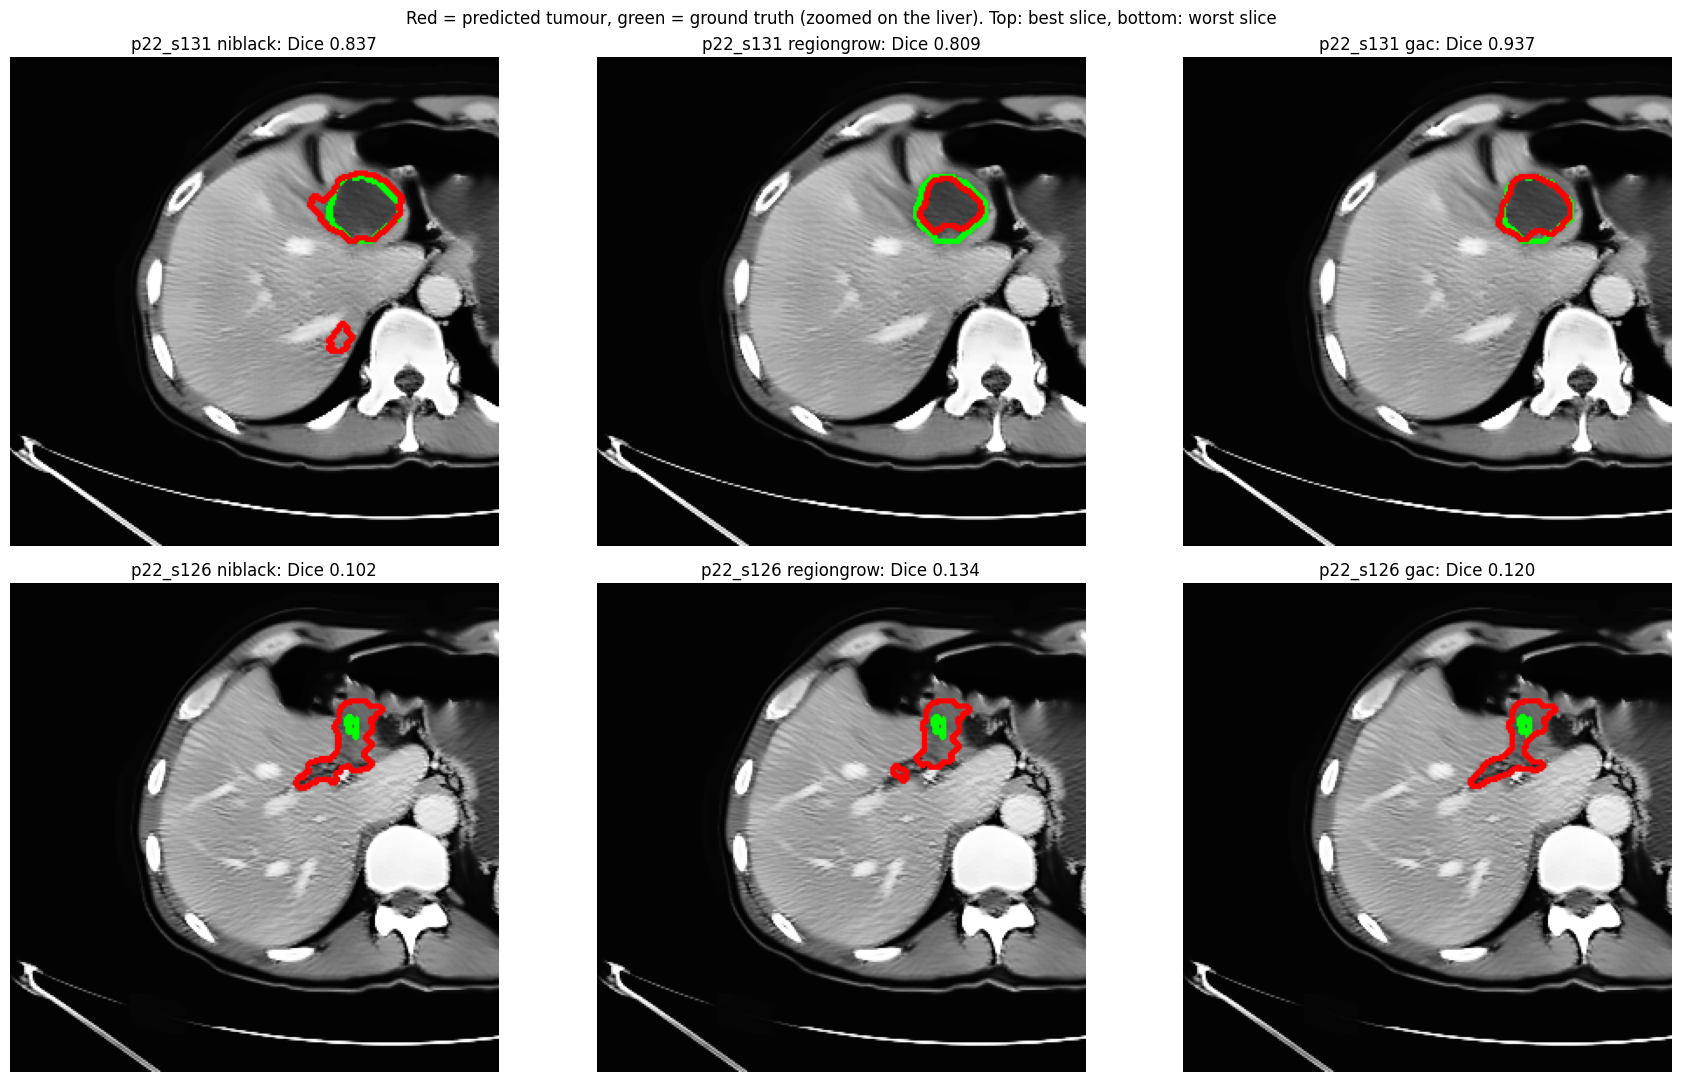

In [17]:
# C is final if comparable to B
mean_dice = results.groupby("method")["Dice"].mean()
if mean_dice["gac"] >= mean_dice["regiongrow"] - 0.02:
    best_method = "gac"
else:
    best_method = "regiongrow"
print("final method:", best_method)

# best and worst slice of the final method
final_dice = results[results.method == best_method].set_index("slice")["Dice"]
best_sid = final_dice.idxmax()
worst_sid = final_dice.idxmin()

# save the comparison figure for the report
panel_slices = [best_sid, worst_sid]
fig, ax = plt.subplots(2, 3, figsize=(18, 11))
for r in range(2):
    s = panel_slices[r]
    for c in range(3):
        method = METHODS[c]
        _, enhanced_img, _, gt_mask = load(ENH + "/" + s + "_enh.png")
        pred_mask = cv2.imread(OUT + "/" + method + "/" + s + "_tumour_pred.png", 0) > 0
        ax[r, c].imshow(overlay(enhanced_img, pred_mask, gt_mask)[r0:r1, c0:c1])
        ax[r, c].axis("off")
        ax[r, c].set_title(f"{s} {method}: Dice {dice(pred_mask, gt_mask):.3f}")
plt.suptitle("Red = predicted tumour, green = ground truth (zoomed on the liver). Top: best slice, bottom: worst slice")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_overlays.png", dpi=120)
plt.show()

## Step 8: Failed cases

Slices with Dice below 0.7 and the measured reasons.

In [18]:
# ---- failed cases: slices with Dice < 0.7 and the measured reasons ----
# best_method = the final method chosen above
best = results[results.method == best_method].sort_values("Dice")
failed = best[best.Dice < 0.7]


def hu(ct, mask):
    # median HU inside a mask
    if mask.any():
        return float(np.median(ct[mask]))
    else:
        return float("nan")


def diagnose(slice_id, img, liver, pred_mask, gt_mask):
    # measure why the slice failed: size, contrast in HU, position, and which pipeline step went wrong
    ct = np.load(GT + "/" + slice_id + "_ct.npy")
    missed = gt_mask & ~pred_mask
    leaked = pred_mask & ~gt_mask
    reasons = []

    ref = liver & ~gt_mask                                                # normal liver around the tumour
    contrast = hu(ct, ref) - hu(ct, gt_mask)
    noise = ct[ref].std()
    if gt_mask.sum() < 300:
        reasons.append(f"small tumour ({int(gt_mask.sum())} px): partial-volume effect, its edge HU blends into the liver")
    if contrast / noise < 1:
        low_text = ", LOW)"
    else:
        low_text = ")"
    reasons.append(f"tumour {contrast:.0f} HU darker than liver, liver noise {noise:.0f} HU (contrast/noise {contrast / noise:.2f}" + low_text)
    in_roi = (gt_mask & liver_roi(liver)).sum() / max(gt_mask.sum(), 1)
    if in_roi < 0.8:
        reasons.append(f"{1 - in_roi:.0%} of the tumour lies in the liver rim that is left out of the search area")

    start = dark_candidates(img, liver)        # the dark candidates the active contour starts from
    if not (start & gt_mask).any():
        reasons.append("step that failed: dark candidate detection (nothing started on the tumour)")
    elif not (pred_mask & gt_mask).any():
        reasons.append("step that failed: clean-up after dark candidate detection removed everything it found on the tumour")
    elif leaked.sum() >= missed.sum():
        reasons.append(f"step that failed: the active contour leaked {int(leaked.sum())} px into tissue of {hu(ct, leaked):.0f} HU "
                       f"(tumour {hu(ct, gt_mask):.0f} HU, neighbours {hu(ct, ref):.0f} HU): similar HU, no edge to stop at")
    else:
        reasons.append(f"step that failed: the active contour stopped early, missed {int(missed.sum())} px of {hu(ct, missed):.0f} HU "
                       f"(found part {hu(ct, pred_mask & gt_mask):.0f} HU)")
    return "; ".join(reasons), ct, missed, leaked, ref

In [19]:
# write the failed-case table and a diagnosis figure for the 3 worst slices
lines = []
lines.append(f"# Phase 2 failed cases: {NAME} (tumour segmentation)")
lines.append("")
lines.append(f"Final method: **{best_method}** (mean Dice {best.Dice.mean():.3f}). Slices with Dice < 0.7: {len(failed)} of {len(best)}.")
lines.append("")
lines.append("| Slice | Dice (" + best_method + ") | Ground-truth pixels | Predicted pixels | Measured reasons |")
lines.append("|---|---|---|---|---|")

k = 0
for _, row in failed.iterrows():
    _, enhanced_img, liver_mask, gt_mask = load(ENH + "/" + row.slice + "_enh.png")
    pred_mask = cv2.imread(OUT + "/" + best_method + "/" + row.slice + "_tumour_pred.png", 0) > 0
    why, ct, missed, leaked, ref = diagnose(row.slice, enhanced_img, liver_mask, pred_mask, gt_mask)
    lines.append(f"| {row.slice} | {row.Dice:.3f} | {int(gt_mask.sum())} | {int(pred_mask.sum())} | {why} |")

    if k < 3:                                                   # diagnosis figure for the 3 worst slices
        # crop around the tumour, the prediction and the liver with a 30 pixel border
        ys, xs = np.where(gt_mask | pred_mask | liver_mask)
        y0 = max(ys.min() - 30, 0)
        y1 = ys.max() + 30
        x0 = max(xs.min() - 30, 0)
        x1 = xs.max() + 30
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
        ax[0].imshow(overlay(enhanced_img, pred_mask, gt_mask)[y0:y1, x0:x1])
        ax[0].axis("off")
        ax[0].set_title(f"{row.slice}: red = predicted, green = truth (Dice {row.Dice:.3f})")

        # HU histograms of the truth, the surroundings, the missed and the leaked pixels
        hist_masks = [gt_mask, ref, missed, leaked]
        hist_names = ["tumour (truth)", "surrounding tissue", "missed", "leaked"]
        hist_colours = ["green", "grey", "orange", "red"]
        for i in range(4):
            mask = hist_masks[i]
            if mask.any():
                ax[1].hist(ct[mask], bins=60, range=(-100, 250), alpha=0.5, density=True,
                           label=f"{hist_names[i]} ({int(mask.sum())} px)", color=hist_colours[i])
        ax[1].set_xlabel("HU")
        ax[1].set_ylabel("density")
        ax[1].legend(fontsize=8)
        ax[1].set_title("HU histograms")
        plt.tight_layout()
        plt.savefig(FAILED + "/" + NAME + "_" + row.slice + "_" + best_method + "_diagnosis.png", dpi=110)
        plt.close()
    k = k + 1

if failed.empty:
    lines.append("| - | - | - | - | no slice below 0.7 |")
lines.append("")
lines.append("Diagnosis figures (overlay + HU histograms of truth, surroundings, missed and leaked pixels) for the 3 worst slices are saved next to this file.")

report_text = "\n".join(lines)
with open(FAILED + "/" + NAME + "_phase2_failed_cases.md", "w") as fh:
    fh.write(report_text)
print(report_text)

# Phase 2 failed cases: kritikaa (tumour segmentation)

Final method: **gac** (mean Dice 0.707). Slices with Dice < 0.7: 3 of 12.

| Slice | Dice (gac) | Ground-truth pixels | Predicted pixels | Measured reasons |
|---|---|---|---|---|
| p22_s126 | 0.120 | 57 | 892 | small tumour (57 px): partial-volume effect, its edge HU blends into the liver; tumour 55 HU darker than liver, liver noise 29 HU (contrast/noise 1.92); step that failed: the active contour leaked 835 px into tissue of 55 HU (tumour 50 HU, neighbours 105 HU): similar HU, no edge to stop at |
| p22_s137 | 0.221 | 153 | 472 | small tumour (153 px): partial-volume effect, its edge HU blends into the liver; tumour 34 HU darker than liver, liver noise 26 HU (contrast/noise 1.31); step that failed: the active contour leaked 403 px into tissue of 59 HU (tumour 68 HU, neighbours 102 HU): similar HU, no edge to stop at |
| p22_s127 | 0.591 | 441 | 587 | tumour 54 HU darker than liver, liver noise 26 HU (contrast/noise 2.08); step t

## Step 9: Parameter sensitivity

Mean Dice while K_DARK changes.

In [20]:
# ---- parameter sensitivity: mean Dice of the final method while K_DARK changes ----
chosen = K_DARK
sweep_rows = []
for value in [1.0, 1.5, 2.0, 2.5, 3.0]:
    K_DARK = value                                         # the segmentation function reads this setting
    scores = []
    for f in files:
        slice_id, enhanced_img, liver_mask, gt_mask = load(f)
        scores.append(dice(segment_gac(enhanced_img, liver_mask), gt_mask))
    row = {}
    row["K_DARK"] = value
    row["mean Dice"] = np.mean(scores)
    row["std Dice"] = np.std(scores)
    sweep_rows.append(row)
K_DARK = chosen                                            # put the chosen value back

sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(OUT + "/phase2_sensitivity.csv", index=False)
print(sweep.round(3).to_string(index=False))

 K_DARK  mean Dice  std Dice
    1.0      0.603     0.261
    1.5      0.681     0.260
    2.0      0.707     0.257
    2.5      0.725     0.264
    3.0      0.689     0.302


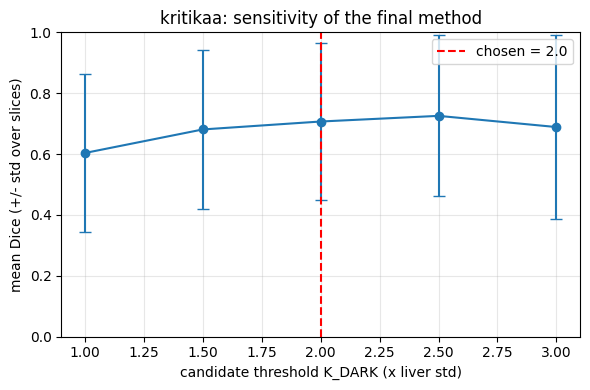

In [21]:
# save the sensitivity figure for the report
plt.figure(figsize=(6, 4))
plt.errorbar(sweep["K_DARK"], sweep["mean Dice"], yerr=sweep["std Dice"], marker="o", capsize=4)
plt.axvline(chosen, color="red", linestyle="--", label=f"chosen = {chosen}")
plt.xlabel("candidate threshold K_DARK (x liver std)")
plt.ylabel("mean Dice (+/- std over slices)")
plt.ylim(0, 1)
plt.title(f"{NAME}: sensitivity of the final method")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_sensitivity.png", dpi=120)
plt.show()